# Greenhouse Temperature Before Photo Sessions

This notebook preserves the supplied analysis and its stored results. Computer-specific data paths have been replaced with `GREENHOUSE_DATA_DIR` (default: `data/2.Validation`). Run cells in order after configuring the data.

For command-line use, run `multi_figure_graph.py`. See `README.md` for results and `docs/METHODS.md` for the time-origin and condition-label limitations.


In [27]:
#check that recordings line up 
import io
import json
import zipfile
from pathlib import Path

import pandas as pd

import os
BASE = Path(os.environ.get("GREENHOUSE_DATA_DIR", "data/2.Validation"))
LABELS = BASE / "라벨링데이터"
SENSORS = BASE / "환경센서"


def files_in(folder, ending):
    """Yield (file name, bytes) from a folder, including files inside zips."""
    for f in folder.rglob("*"):
        if f.suffix.lower() == ending:
            yield f.stem, f.read_bytes()
        elif f.suffix.lower() == ".zip":
            with zipfile.ZipFile(f) as z:
                for info in z.infolist():
                    if info.filename.lower().endswith(ending):
                        yield Path(info.filename).stem, z.read(info)


labels = []
for stem, data in files_in(LABELS, ".json"):
    d = json.loads(data.decode("utf-8-sig"))
    a = d["annotations"]
    labels.append({"stem": stem, "date": d["description"]["date"], "disease": a.get("disease"),
                   "grow": a.get("grow"), "risk": a.get("risk")})
labels = pd.DataFrame(labels)

farms = {}
for stem, data in files_in(SENSORS, ".csv"):
    farms[stem] = pd.read_csv(io.BytesIO(data), encoding="cp949", usecols=["농지명"], nrows=1).iloc[0, 0]
codes = {name: f"Farm {i + 1:02d}" for i, name in enumerate(sorted(set(farms.values())))}

labels["farm"] = labels.stem.map(farms).map(codes)
print("Labels:", len(labels), "| sensor files:", len(farms), "| labels with a matching CSV:", labels.farm.notna().sum())
print(labels.disease.value_counts())
print(labels.grow.value_counts().sort_index())
print(labels.groupby("farm").agg(photos=("stem", "size"), dates=("date", "nunique"),
                                 first=("date", "min"), last=("date", "max"),
                                 stages=("grow", "nunique")).sort_values("dates", ascending=False))

Labels: 26866 | sensor files: 13433 | labels with a matching CSV: 26866
disease
00    11084
a1     3574
a2     2454
b7     2096
b8     2038
b6     1856
c1     1442
c2     1318
b1     1004
Name: count, dtype: int64
grow
11     7730
12    15562
13     3574
Name: count, dtype: int64
         photos  dates     first      last  stages
farm                                              
Farm 01   15782     17  20211006  20220113       2
Farm 04    7730      4  20210915  20210928       1
Farm 02     818      1  20211007  20211007       1
Farm 03    2536      1  20211008  20211008       1


In [15]:
# Remove duplicate label files
labels = labels.drop_duplicates("stem")
print("Unique labels:", len(labels))

# Which farms have which diseases and growth stages?
print(pd.crosstab(labels.farm, labels.disease))
print(pd.crosstab(labels.farm, labels.grow))
print(pd.crosstab(labels.disease, labels.grow))

# Farm 01 date by date: number of photos, disease codes and growth codes
f1 = labels[labels.farm == "Farm 01"]
print(f1.groupby("date").agg(photos=("stem", "size"),
                             diseases=("disease", lambda s: ", ".join(sorted(s.unique()))),
                             stages=("grow", lambda s: ", ".join(map(str, sorted(s.unique()))))))

Unique labels: 13433
disease    00    a1    a2   b1   b6    b7    b8   c1   c2
farm                                                     
Farm 01     0  1787  1227  502  928  1048  1019  721  659
Farm 02   409     0     0    0    0     0     0    0    0
Farm 03  1268     0     0    0    0     0     0    0    0
Farm 04  3865     0     0    0    0     0     0    0    0
grow       11    12    13
farm                     
Farm 01     0  6104  1787
Farm 02     0   409     0
Farm 03     0  1268     0
Farm 04  3865     0     0
grow       11    12    13
disease                  
00       3865  1677     0
a1          0     0  1787
a2          0  1227     0
b1          0   502     0
b6          0   928     0
b7          0  1048     0
b8          0  1019     0
c1          0   721     0
c2          0   659     0
          photos    diseases stages
date                               
20211006     764  b6, b7, b8     12
20211007     590  b6, b7, b8     12
20211008     542  b6, b7, b8     12
20211012 

In [16]:
#libraries, folder paths and settings 
import io
import json
import zipfile
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Where the data is, and where outputs are saved
import os
BASE = Path(os.environ.get("GREENHOUSE_DATA_DIR", "data/2.Validation"))
LABELS = BASE / "라벨링데이터"
SENSORS = BASE / "환경센서"
OUT = Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)

# Names for the condition codes
CODE_NAMES = {"00": "Healthy", "a1": "a1", "a2": "a2", "b1": "b1", "b6": "b6",
              "b7": "b7", "b8": "b8", "c1": "c1", "c2": "c2"}

# Air within 2 °C of its dew point counts as near condensation
CONDENSATION_GAP = 2.0

print("Labels folder found:", LABELS.exists())
print("Sensor folder found:", SENSORS.exists())
print("Figures will be saved in:", OUT)

Labels folder found: True
Sensor folder found: True
Figures will be saved in: outputs


In [17]:
#helper that reads files inside the zips 
def files_in(folder, ending): 
    for f in folder.rglob("*"):
        if f.suffix.lower() == ending: 
            yield f.stem, f.read_bytes
        elif f.suffix.lower() == ".zip":
            z = zipfile.ZipFile(f)
            for info in z.infolist():
                if info.filename.lower().endswith(ending): 
                    yield Path(info.filename).stem, (lambda z=z, i=info: z.read(i))

In [18]:
#load the labels 
labels =[]
for stem, read in files_in(LABELS, ".json"): 
    d = json.loads(read().decode("utf-8-sig"))
    desc, a = d["description"], d["annotations"]
    labels.append({"stem": stem, "date": pd.to_datetime(desc["date"]),
                   "hour":str(desc.get("time", ""))[:2], "code": a.get("disease"), "risk": a.get("risk")})

# Each label appears twice in the zip, so keep one copy
labels = pd.DataFrame(labels).drop_duplicates("stem")
print(len(labels), "labels")
    

13433 labels


In [19]:
#find each photo's farm and pick Farm 01 
sensors = dict(files_in(SENSORS, ".csv"))

#read only the first row of each CSV to get farm name 
farm_of = {}
for stem in labels.stem: 
    if stem in sensors:
        first = pd.read_csv(io.BytesIO(sensors[stem]()), encoding="cp949", nrows=1)
        farm_of[stem] = first.filter(like="농지").iloc[0, 0]

#replace real farm names with anonymous codes 
codes = {name: f"Farm {i + 1:02d}" for i, name in enumerate(sorted(set(farm_of.values())))}
labels["farm"] = labels.stem.map(farm_of).map(codes)

#keep the farm photographed on the most dates 
farm = labels.groupby("farm").date.nunique().idxmax()
lab = labels[labels.farm == farm]
print(farm, "=", len(lab), "photos on", lab.date.nunique(), "dates")

Farm 01 = 7891 photos on 17 dates


In [20]:
#load the farm's sensor readings 
def read_sensor(data):
    df = pd.read_csv(io.BytesIO(data), encoding="cp949")
    find = lambda word: next(c for c in df.columns if word in c)
    return pd.DataFrame({"time": pd.to_datetime(df[find("측정시각")]), "temp": df[find("온도")],
                         "rh": df[find("습도")], "co2": df[find("CO2")], "dew": df[find("이슬점")]})

#one sensor file per condition
picks = lab.drop_duplicates(["code", "date", "hour"])
frames = []
for _, row in picks.iterrows():
    s = read_sensor(sensors[row.stem]())
    s["code"], s["photo_date"] = row.code, row.date
    frames.append(s)

env_all = pd.concat(frames).drop_duplicates(["photo_date", "time"]).sort_values("time")
env = env_all.drop_duplicates(["code", "time"]).copy()
env["gap"] = env.temp - env.dew
print(len(picks), "sensor files read,", len(env), "readings")
env.head()
    

66 sensor files read, 4050 readings


,time,temp,rh,co2,dew,code,photo_date,gap
0,2021-10-04 09:20:00,25.9,71.5,445.0,20.5,b8,2021-10-06,5.4
0,2021-10-04 09:30:00,26.2,71.1,445.0,20.5,b7,2021-10-06,5.7
0,2021-10-04 09:30:00,26.2,71.1,445.0,20.5,b8,2021-10-16,5.7
0,2021-10-04 09:40:00,26.7,70.5,442.0,21.2,b6,2021-10-06,5.5
1,2021-10-04 09:40:00,26.7,70.5,442.0,21.2,b8,2021-10-16,5.5


In [21]:
#table of condition periods 
PALETTE = ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#e6ab02", "#a6761d", "#666666"]
from matplotlib.colors import to_rgb, to_hex

PALETTE = ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#e6ab02", "#a6761d", "#666666"]
MUTE = 0.35      # 0 = original colours, 1 = fully grey


def mute(colour, amount=MUTE, grey="#8c8c8c"):
    """Blend a colour towards grey to make it less vibrant."""
    c, g = to_rgb(colour), to_rgb(grey)
    return to_hex([x * (1 - amount) + y * amount for x, y in zip(c, g)])


per = lab.groupby("code").agg(first=("date", "min"), last=("date", "max"),
                              photos=("stem", "size"), dates=("date", "nunique")).sort_values("first")
per["name"] = [CODE_NAMES.get(c, c) for c in per.index]
per["colour"] = [mute(PALETTE[i % len(PALETTE)]) for i in range(len(per))]
per["label"] = [f"{n}\n{a.day} {a:%b} \u2013 {b.day} {b:%b}" if a != b else f"{n}\n{a.day} {a:%b %Y}"
                for n, a, b in zip(per.name, per["first"], per["last"])]
per

,first,last,photos,dates,name,colour,label
code,,,,,,,
b6,2021-10-06,2021-10-12,928,4,b6,#43987e,b6\n6 Oct – 12 Oct
b7,2021-10-06,2021-10-12,1048,4,b7,#be6f32,b7\n6 Oct – 12 Oct
b8,2021-10-06,2021-10-17,1019,6,b8,#7d7aa5,b8\n6 Oct – 17 Oct
a2,2021-10-13,2021-10-19,1227,5,a2,#c74c8b,a2\n13 Oct – 19 Oct
c2,2021-11-22,2021-11-22,659,1,c2,#739d45,c2\n22 Nov 2021
c1,2021-12-01,2021-12-01,721,1,c1,#c6a032,c1\n1 Dec 2021
a1,2021-12-09,2021-12-13,1787,3,a1,#9d7e44,a1\n9 Dec – 13 Dec
b1,2022-01-13,2022-01-13,502,1,b1,#737373,b1\n13 Jan 2022


In [22]:
#figure style and title helpers 
TITLE_PT, SUBTITLE_PT, AXIS_PT, TICK_PT, NOTE_PT = 16, 10, 13, 11, 9
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "Helvetica", "DejaVu Sans"],
    "font.size": TICK_PT, "axes.labelsize": AXIS_PT,
    "xtick.labelsize": TICK_PT, "ytick.labelsize": TICK_PT,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#444444", "savefig.dpi": 200, "savefig.facecolor": "white",
})

VARIABLES = [("temp", "Temperature (\u00b0C)"), ("rh", "Relative humidity (%)"),
             ("gap", "Air temp. minus dew point (\u00b0C)")]


def add_header(fig, title, subtitle, x=0.03, top=0.975):
    h = fig.get_size_inches()[1]
    fig.text(x, top, title, fontsize=TITLE_PT, fontweight="bold", ha="left", va="top")
    y = top - TITLE_PT * 1.45 / 72 / h
    fig.text(x, y, subtitle, fontsize=SUBTITLE_PT, ha="left", va="top", color="#333333")
    return y - SUBTITLE_PT * 1.6 / 72 / h - 0.25 / h


def add_note(fig, text):
    fig.text(0.03, 0.012, text, fontsize=NOTE_PT, color="#666666", ha="left", va="bottom")

In [23]:
import math

# Standard matplotlib look: boxed panels, ticks pointing inwards
plt.rcdefaults()
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans"],
                     "font.size": 9, "axes.linewidth": 0.8, "xtick.direction": "in",
                     "ytick.direction": "in", "savefig.dpi": 300})

Y_MIN, Y_MAX = env_all.dew.min() - 1, env_all.temp.max() + 1
dates = sorted(lab.date.unique())


def plot_session(ax, date):
    w = env_all[env_all.photo_date == date].set_index("time").sort_index()
    code = lab.loc[lab.date == date, "code"].iloc[0]
    hours = (w.index - w.index.max()).total_seconds() / 3600
    ax.fill_between(hours, w.dew, w.temp, where=(w.temp - w.dew) < CONDENSATION_GAP,
                    color="#f4a582", lw=0)
    ax.plot(hours, w.temp, color=per.loc[code, "colour"], lw=1.2)
    ax.plot(hours, w.dew, color="0.4", lw=0.8, ls="--")
    ax.set_title(f"{date:%Y-%m-%d} ({CODE_NAMES.get(code, code)})", fontsize=9, fontweight="bold")
    ax.set_xlim(-48, 0)
    ax.set_xticks([-48, -36, -24, -12, 0])
    ax.set_ylim(Y_MIN, Y_MAX)
    ax.grid(color="0.9", lw=0.5)

In [24]:
(OUT / "sessions").mkdir(exist_ok=True)

for date in dates:
    date = pd.Timestamp(date)
    fig, ax = plt.subplots(figsize=(5, 3.5))
    plot_session(ax, date)
    ax.set_xlabel("Hours before photo")
    ax.set_ylabel("Temperature (\u00b0C)")
    fig.tight_layout()
    fig.savefig(OUT / "sessions" / f"session_{date:%Y%m%d}.png")
    plt.close(fig)

print(len(dates), "figures saved in", (OUT / "sessions").resolve())

17 figures saved in outputs\sessions


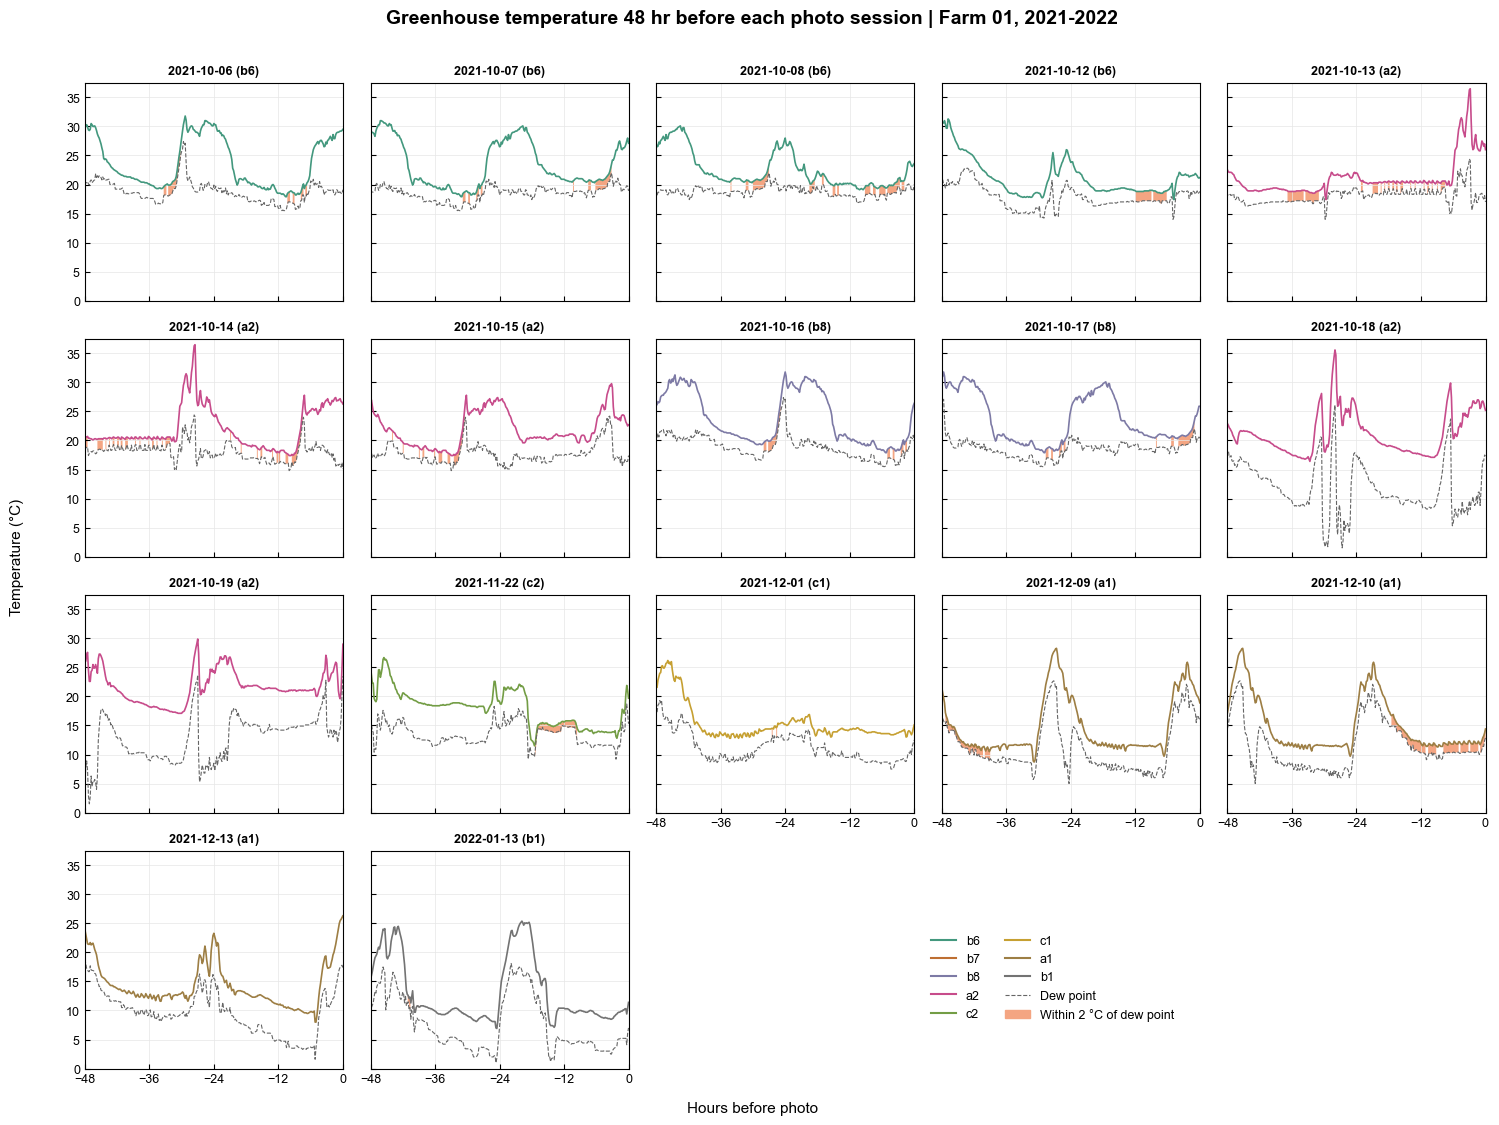

Saved: outputs\f4_photo_sessions.png


In [28]:
cols = 5
rows = math.ceil(len(dates) / cols)
fig, axs = plt.subplots(rows, cols, figsize=(15, 2.6 * rows + 1), sharex=True, sharey=True)
axs = axs.ravel()

for ax, date in zip(axs, dates):
    plot_session(ax, pd.Timestamp(date))
for k, ax in enumerate(axs):
    if k >= len(dates):
        ax.axis("off")
    elif k + cols >= len(dates):
        ax.tick_params(labelbottom=True)

fig.suptitle(f"Greenhouse temperature 48 hr before each photo session | {farm}, 2021-2022",
             fontsize=14, fontweight="bold")
fig.supxlabel("Hours before photo", fontsize=11)
fig.supylabel("Temperature (\u00b0C)", fontsize=11, x=0.005)

handles = [plt.Line2D([], [], color=r.colour, lw=1.5, label=r["name"]) for _, r in per.iterrows()]
handles += [plt.Line2D([], [], color="0.4", lw=0.8, ls="--", label="Dew point"),
            plt.Rectangle((0, 0), 1, 1, color="#f4a582",
                          label=f"Within {CONDENSATION_GAP:g} \u00b0C of dew point")]
fig.legend(handles=handles, loc="center", bbox_to_anchor=(0.7, 0.13), ncol=2, fontsize=9, frameon=False)

fig.tight_layout(rect=[0.015, 0, 1, 0.97])
fig.savefig(OUT / "f4_photo_sessions.png")
plt.show()
print("Saved:", (OUT / "f4_photo_sessions.png").resolve())

In [26]:
print((OUT / "f4_photo_sessions.png").resolve())
print((OUT / "sessions").resolve())


outputs\f4_photo_sessions.png
outputs\sessions
